In [2]:
# import system libs
import os
import time
import shutil
import pathlib
import itertools

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras import regularizers
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import regularizers

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print ('All modules loaded')

2024-05-31 11:27:37.058163: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-31 11:27:37.058254: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-31 11:27:37.191841: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


All modules loaded


In [3]:
# Generate data paths with labels
data_dir2 = '/kaggle/input/chest-x-ray/DATASET'
data_dir = '/kaggle/input/multiclass-chest-xray-disease-dataset/chest_xray/train'


filepaths = []
labels = []

folds = os.listdir(data_dir)
# folds.remove('NORMAL')
for fold in folds:
    foldpath = os.path.join(data_dir, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)
        filepaths.append(fpath)
        labels.append(fold)
        
        
folds = ['Pleural' , 'Cardiomegaly']
# folds = os.listdir(data_dir)
# folds.remove('NORMAL')
for fold in folds:
    foldpath = os.path.join(data_dir2, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)
        filepaths.append(fpath)
        labels.append(fold)

# Concatenate data paths with labels into one dataframe
Fseries = pd.Series(filepaths, name= 'filepaths')
Lseries = pd.Series(labels, name='labels')
df = pd.concat([Fseries, Lseries], axis= 1)

In [4]:
df

,filepaths,labels
0,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
1,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
2,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
3,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
4,/kaggle/input/multiclass-chest-xray-disease-da...,PNEUMONIA
...,...,...
18289,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly
18290,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly
18291,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly
18292,/kaggle/input/chest-x-ray/DATASET/Cardiomegaly...,Cardiomegaly


In [5]:
# train dataframe
train_df, dummy_df = train_test_split(df,  train_size= 0.8, shuffle= True, random_state= 123)

# valid and test dataframe
valid_df, test_df = train_test_split(dummy_df,  train_size= 0.6, shuffle= True, random_state= 123)

In [6]:
# croped image size
batch_size = 64
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels)

# Recommended : use custom function for test data batch size, else we can use normal batch size.
ts_length = len(test_df)
test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

# This function which will be used in image data generator for data augmentation, it just take the image and return it again.
def scalar(img):
    return img

tr_gen = ImageDataGenerator(preprocessing_function= scalar)
ts_gen = ImageDataGenerator(preprocessing_function= scalar)

train_gen = tr_gen.flow_from_dataframe( train_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                    color_mode= 'rgb', shuffle= True, batch_size= batch_size)

valid_gen = ts_gen.flow_from_dataframe( valid_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                    color_mode= 'rgb', shuffle= True, batch_size= batch_size)

# Note: we will use custom test_batch_size, and make shuffle= false
test_gen = ts_gen.flow_from_dataframe( test_df, x_col= 'filepaths', y_col= 'labels', target_size= img_size, class_mode= 'categorical',
                                    color_mode= 'rgb', shuffle= False, batch_size= test_batch_size)

Found 14635 validated image filenames belonging to 7 classes.
Found 2195 validated image filenames belonging to 7 classes.
Found 1464 validated image filenames belonging to 7 classes.


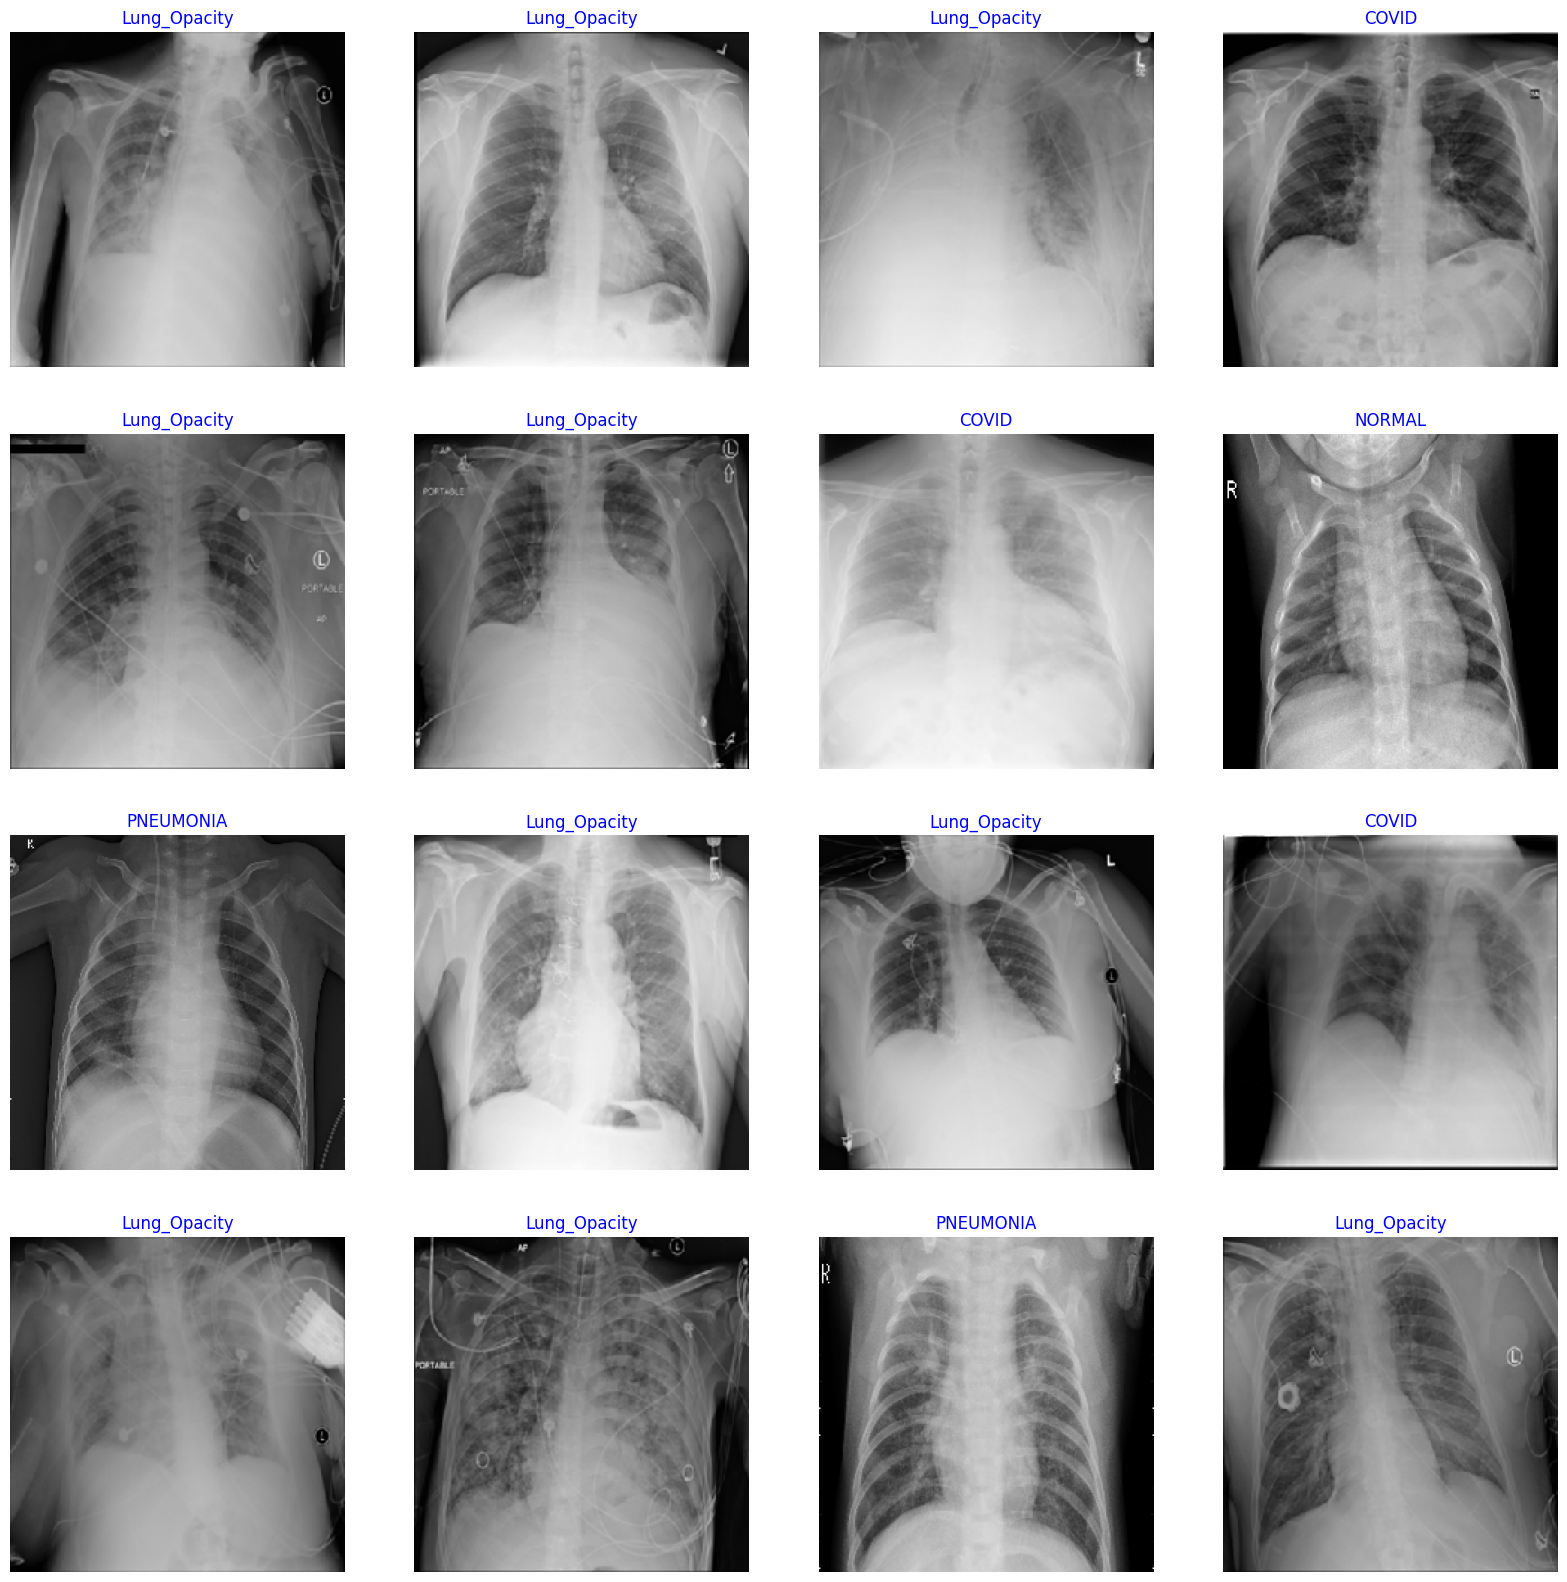

In [8]:
g_dict = train_gen.class_indices      # defines dictionary {'class': index}
classes = list(g_dict.keys())       # defines list of dictionary's kays (classes), classes names : string
images, labels = next(train_gen)      # get a batch size samples from the generator

plt.figure(figsize= (20, 20))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    image = images[i] / 255       # scales data to range (0 - 255)
    plt.imshow(image)
    index = np.argmax(labels[i])  # get image index
    class_name = classes[index]   # get class of image
    plt.title(class_name, color= 'blue', fontsize= 12)
    plt.axis('off')
plt.show()

In [9]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adamax

# Define image size, channels, and number of classes
img_size = (224, 224)
channels = 3
class_count = len(list(train_gen.class_indices.keys()))

# Load ResNet50 pre-trained model
base_model = ResNet50(include_top=False, weights='imagenet', input_shape=(img_size[0], img_size[1], channels))

# Add Global Average Pooling layer
x = GlobalAveragePooling2D()(base_model.output)

# Output layer
output = Dense(class_count, activation='softmax')(x)

# Define new model
model = Model(inputs=base_model.input, outputs=output)

# Freeze the base model's layers
base_model.trainable = False

# Compile the model
model.compile(Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [10]:
class_names = list(train_gen.class_indices.keys())
print(class_names)


['COVID', 'Cardiomegaly', 'Lung_Opacity', 'NORMAL', 'PNEUMONIA', 'Pleural', 'TURBERCULOSIS']


In [11]:
batch_size = 64   # set batch size for training
epochs = 10   # number of all epochs in training

history = model.fit(x= train_gen, epochs= epochs, verbose= 1, validation_data= valid_gen, 
                    validation_steps= None, shuffle= False)

Epoch 1/10
  2/229 ━━━━━━━━━━━━━━━━━━━━ 20s 90ms/step - accuracy: 0.1289 - loss: 2.4039 

I0000 00:00:1717154992.687461     113 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1717154992.739607     113 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


229/229 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.6263 - loss: 1.0562

W0000 00:00:1717155207.089330     111 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update
W0000 00:00:1717155213.617438     111 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


229/229 ━━━━━━━━━━━━━━━━━━━━ 270s 1s/step - accuracy: 0.6267 - loss: 1.0550 - val_accuracy: 0.8109 - val_loss: 0.5381
Epoch 2/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 126s 551ms/step - accuracy: 0.8185 - loss: 0.5088 - val_accuracy: 0.8533 - val_loss: 0.4151
Epoch 3/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 126s 550ms/step - accuracy: 0.8627 - loss: 0.4024 - val_accuracy: 0.8802 - val_loss: 0.3616
Epoch 4/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 125s 544ms/step - accuracy: 0.8836 - loss: 0.3412 - val_accuracy: 0.8888 - val_loss: 0.3247
Epoch 5/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 121s 528ms/step - accuracy: 0.8930 - loss: 0.3129 - val_accuracy: 0.8970 - val_loss: 0.3000
Epoch 6/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 124s 541ms/step - accuracy: 0.9014 - loss: 0.2884 - val_accuracy: 0.9016 - val_loss: 0.2791
Epoch 7/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 125s 548ms/step - accuracy: 0.9115 - loss: 0.2624 - val_accuracy: 0.9025 - val_loss: 0.2688
Epoch 8/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 125s 548ms/step - accuracy: 0.9202 - loss: 0.2436 

In [12]:
test_loss, test_accuracy = model.evaluate(test_gen)
print("Test Accuracy:", test_accuracy)


 2/24 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.8893 - loss: 0.2876

W0000 00:00:1717156406.393890     110 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


24/24 ━━━━━━━━━━━━━━━━━━━━ 29s 976ms/step - accuracy: 0.8955 - loss: 0.2765
Test Accuracy: 0.8989071249961853


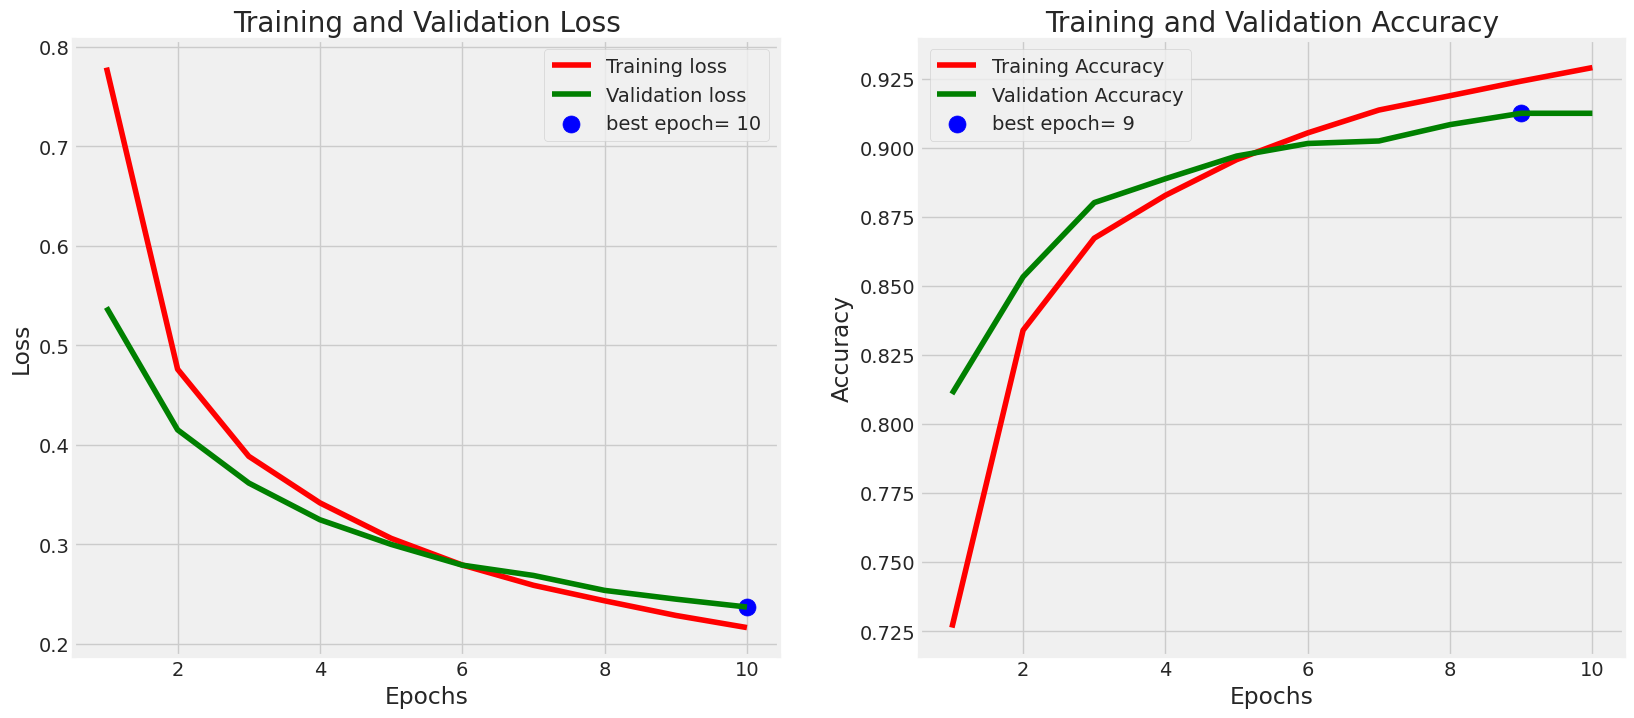

In [13]:
# Define needed variables
tr_acc = history.history['accuracy']
tr_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize= (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

In [14]:
ts_length = len(test_df)
test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

train_score = model.evaluate(train_gen, steps= test_steps, verbose= 1)
valid_score = model.evaluate(valid_gen, steps= test_steps, verbose= 1)
test_score = model.evaluate(test_gen, steps= test_steps, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

24/24 ━━━━━━━━━━━━━━━━━━━━ 12s 484ms/step - accuracy: 0.9349 - loss: 0.2105
24/24 ━━━━━━━━━━━━━━━━━━━━ 12s 490ms/step - accuracy: 0.9106 - loss: 0.2332
24/24 ━━━━━━━━━━━━━━━━━━━━ 13s 523ms/step - accuracy: 0.8955 - loss: 0.2765
Train Loss:  0.2145737260580063
Train Accuracy:  0.9329426884651184
--------------------
Validation Loss:  0.23675478994846344
Validation Accuracy:  0.91015625
--------------------
Test Loss:  0.27056553959846497
Test Accuracy:  0.8989071249961853


In [16]:
preds = model.predict(test_gen)
y_pred = np.argmax(preds, axis=1)

 2/24 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step

W0000 00:00:1717156624.263129     113 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 471ms/step


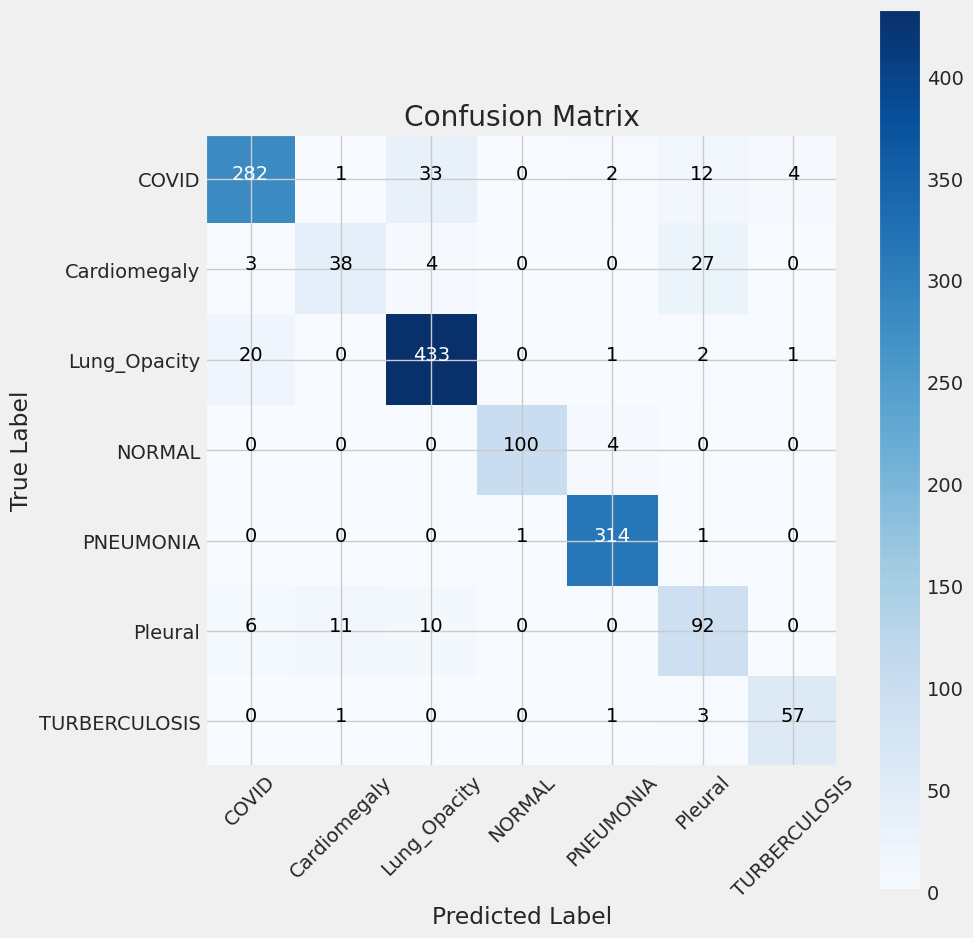

In [17]:
g_dict = test_gen.class_indices
classes = list(g_dict.keys())

# Confusion matrix
cm = confusion_matrix(test_gen.classes, y_pred)

plt.figure(figsize= (10, 10))
plt.imshow(cm, interpolation= 'nearest', cmap= plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation= 45)
plt.yticks(tick_marks, classes)


thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.show()


In [18]:
# Classification report
print(classification_report(test_gen.classes, y_pred, target_names= classes))


               precision    recall  f1-score   support

        COVID       0.91      0.84      0.87       334
 Cardiomegaly       0.75      0.53      0.62        72
 Lung_Opacity       0.90      0.95      0.92       457
       NORMAL       0.99      0.96      0.98       104
    PNEUMONIA       0.98      0.99      0.98       316
      Pleural       0.67      0.77      0.72       119
TURBERCULOSIS       0.92      0.92      0.92        62

     accuracy                           0.90      1464
    macro avg       0.87      0.85      0.86      1464
 weighted avg       0.90      0.90      0.90      1464



In [19]:
model.save('chest_x-raysResNet50-FINAL.h5')